<h1 style="text-align: center; color: #2c3e50;">
    Hate Speech Analysis in Tweets
</h1>
<hr style="height: 2px; border: none; background-color: #2c3e50;">

- Hate Speech in Tweets analysis consists of automatically identifying and classifying hate speech in Twitter posts. Using real data obtained from the *data.world* website, this study applies a sequential neural network model to perform the classification, differentiating between hate speech, attack language and neutrality. The analysis is part of the studies of the TAI - Topics in Artificial Intelligence class.

- A análise de Discurso de Ódio em tweets consiste em identificar e classificar automaticamente discursos de ódio em publicações no Twitter. Utilizando dados reais obtidos do site data.world, este estudo aplica um modelo de rede neural sequencial para realizar a classificação, diferenciando entre hate speech, linguagem ofensiva e neutra. A análise faz parte dos estudos da disciplina TIA - Tópicos em Inteligência Artificial.

word2vec, embedding

<h2 style="color: #34495e;">
    Imported Libraries
</h2>
<hr style="height: 1px; border: none; background-color: #34495e;">

In [1]:
import matplotlib.pyplot as plt
import tensorflow as tf
import pandas as pd
import numpy as np
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import regularizers

<h2 style="color: #34495e;">
    Dataset definition
</h2>
<hr style="height: 1px; border: none; background-color: #34495e;">

In [2]:
df = pd.read_csv('https://query.data.world/s/3w2odrweyv6zurbtbmxsxshcuwpwn3?dws=00000')

In [3]:
df

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...
...,...,...,...,...,...,...,...
24778,25291,3,0,2,1,1,you's a muthaf***in lie &#8220;@LifeAsKing: @2...
24779,25292,3,0,1,2,2,"you've gone and broke the wrong heart baby, an..."
24780,25294,3,0,3,0,1,young buck wanna eat!!.. dat nigguh like I ain...
24781,25295,6,0,6,0,1,youu got wild bitches tellin you lies


In [4]:
class_weight = {0: 1., 1: 2., 2: 2.}

In [5]:
X = df.drop(columns=['class', 'Unnamed: 0'])
y = df['class']

In [6]:
X

,count,hate_speech,offensive_language,neither,tweet
0,3,0,0,3,!!! RT @mayasolovely: As a woman you shouldn't...
1,3,0,3,0,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,3,0,3,0,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,0,2,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,6,0,6,0,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...
...,...,...,...,...,...
24778,3,0,2,1,you's a muthaf***in lie &#8220;@LifeAsKing: @2...
24779,3,0,1,2,"you've gone and broke the wrong heart baby, an..."
24780,3,0,3,0,young buck wanna eat!!.. dat nigguh like I ain...
24781,6,0,6,0,youu got wild bitches tellin you lies


In [7]:
df['tweet_clean'] = df['tweet'].str.replace(r'[^A-Za-z\s]', '', regex=True).str.lower().str.strip()

In [41]:
tokenizer = Tokenizer(num_words=10000)
tokenizer.fit_on_texts(df['tweet_clean'])

X_sequences = tokenizer.texts_to_sequences(df['tweet_clean'])
X_padded = pad_sequences(X_sequences, maxlen=100)

In [45]:
X_additional_features = df[['hate_speech', 'offensive_language', 'neither']].values
X_final = np.concatenate([X_padded, X_additional_features], axis=1)
print("Formato final de X:", X_final.shape)

Formato final de X: (24783, 103)


In [44]:
X_tensor = tf.convert_to_tensor(X_final, dtype=tf.int32)
y_tensor = tf.convert_to_tensor(y.values, dtype=tf.int32)

<tf.Tensor: shape=(24783, 103), dtype=int32, numpy=
array([[0, 0, 0, ..., 0, 0, 3],
       [0, 0, 0, ..., 0, 3, 0],
       [0, 0, 0, ..., 0, 3, 0],
       ...,
       [0, 0, 0, ..., 0, 3, 0],
       [0, 0, 0, ..., 0, 6, 0],
       [0, 0, 0, ..., 0, 0, 3]])>

In [11]:
dataset = tf.data.Dataset.from_tensor_slices((X_tensor, y_tensor))
dataset

<_TensorSliceDataset element_spec=(TensorSpec(shape=(103,), dtype=tf.int32, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))>

In [12]:
train_size = int(0.8 * len(X))
test_size = len(X) - train_size

In [36]:
train_dataset = dataset.take(train_size)

In [14]:
test_dataset = dataset.skip(train_size)

In [15]:
print(f'Tamanho do conjunto de treino: {train_size}')
print(f'Tamanho do conjunto de teste: {test_size}')

Tamanho do conjunto de treino: 19826
Tamanho do conjunto de teste: 4957


<h2 style="color: #34495e;">
    Model definition
</h2>
<hr style="height: 1px; border: none; background-color: #34495e;">

In [17]:
model = models.Sequential()

model.add(layers.Dense(128, activation='relu', input_shape=(103,), kernel_regularizer=regularizers.l2(0.001)))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(3, activation='softmax'))

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [18]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 128)                 │          13,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 21,763 (85.01 KB)

 Trainable params: 21,763 (85.01 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
train_dataset = train_dataset.batch(32)
test_dataset = test_dataset.batch(32)

In [20]:
for x_batch, y_batch in train_dataset.take(1):
    print(x_batch.shape)

(32, 103)


<h2 style="color: #34495e;">
    Model training
</h2>
<hr style="height: 1px; border: none; background-color: #34495e;">

In [21]:
history = model.fit(train_dataset, epochs=15, validation_data=test_dataset, class_weight=class_weight)

Epoch 1/15
620/620 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.5916 - loss: 341.4335 - val_accuracy: 0.7914 - val_loss: 1.2932
Epoch 2/15
620/620 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7032 - loss: 9.9458 - val_accuracy: 0.7926 - val_loss: 0.7824
Epoch 3/15
620/620 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7416 - loss: 2.8292 - val_accuracy: 0.7924 - val_loss: 0.7430
Epoch 4/15
620/620 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7484 - loss: 1.8467 - val_accuracy: 0.7926 - val_loss: 0.7352
Epoch 5/15
620/620 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7552 - loss: 1.5803 - val_accuracy: 0.7924 - val_loss: 0.7342
Epoch 6/15
620/620 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7604 - loss: 1.5286 - val_accuracy: 0.7924 - val_loss: 0.7349
Epoch 7/15
620/620 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7605 - loss: 1.3720 - val_accuracy: 0.7924 - val_loss: 0.7353
Epoch 8/15
620/620 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7631 - loss: 1.3499 - val_accuracy: 

<h2 style="color: #34495e;">
    Model evaluation
</h2>
<hr style="height: 1px; border: none; background-color: #34495e;">

In [22]:
test_loss, test_acc = model.evaluate(test_dataset)

155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7794 - loss: 0.7406


In [23]:
print(f"Perda no teste: {test_loss}")
print(f"Acurácia no teste: {test_acc}")

Perda no teste: 0.7255042195320129
Acurácia no teste: 0.7924147844314575


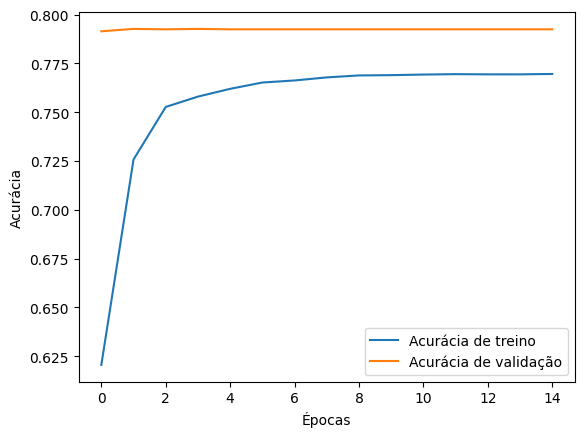

In [24]:
plt.plot(history.history['accuracy'], label='Acurácia de treino')
plt.plot(history.history['val_accuracy'], label='Acurácia de validação')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()
plt.show()

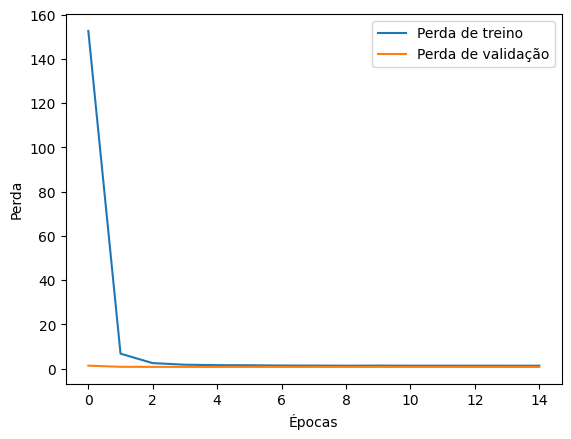

In [25]:
plt.plot(history.history['loss'], label='Perda de treino')
plt.plot(history.history['val_loss'], label='Perda de validação')
plt.xlabel('Épocas')
plt.ylabel('Perda')
plt.legend()
plt.show()

In [31]:
def token_identifier(tweet):
    tokenizer = Tokenizer()
    tweet_sequence = tokenizer.texts_to_sequences([tweet])
    tweet_padded = pad_sequences(tweet_sequence, maxlen=103)
    prediction = model.predict(tweet_padded)
    predicted_class = prediction.argmax(axis=-1)
    return prediction, predicted_class

In [33]:
token_identifier("eu odeio gay")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


(array([[0.02922413, 0.79720265, 0.17357324]], dtype=float32),
 array([1], dtype=int64))

In [46]:
tweets_ofensivos = [
    "Você não vale nada, ninguém te suporta!",
    "Esse cara só fala besteira, ninguém quer te ouvir!",
    "Como você é burro, não sabe de nada.",
    "Vai se esconder, ninguém quer saber de você!",
    "Seu idiota, não sabe nem escrever direito.",
    "Você só fala merda, cala a boca!",
    "Sai daqui, ninguém gosta de você!",
    "Inútil! Não serve pra nada!",
    "Cala essa boca, ninguém liga pro que você diz!",
    "Esse cara é um completo idiota!",
    "Como alguém tão estúpido pode existir?",
    "Ninguém aguenta mais sua cara, vai embora!",
    "Você não passa de um babaca!",
    "Essa gente só sabe reclamar, não fazem nada de útil.",
    "Tão ignorante que chega a dar vergonha.",
    "Que comentário ridículo, vai estudar!",
    "Você é uma vergonha pra todos nós!",
    "Sai daqui, lixo!",
    "Não entendo como alguém tão estúpido tem seguidores.",
    "É por causa de gente como você que o mundo está uma bagunça.",
    "Seu fracassado, nunca vai chegar a lugar nenhum.",
    "Cretino! Não sabe o que está falando.",
    "Ninguém suporta mais ver suas postagens idiotas.",
    "Idiota demais pra entender o que está acontecendo.",
    "Vai se ferrar! Ninguém precisa da sua opinião.",
    "Que piada! Você é irrelevante!",
    "Você é tão insignificante que chega a ser triste.",
    "Sai da internet, ninguém te aguenta mais!",
    "Você só atrapalha, não serve pra nada.",
    "Cala essa boca de uma vez!",
    "Ridículo demais pra ser levado a sério.",
    "Seu hipócrita, cala a boca!",
    "Ninguém liga pro que você diz, inútil!",
    "Apenas um idiota tentando chamar atenção.",
    "Você é uma piada, cara!",
    "Ninguém quer saber da sua opinião estúpida!",
    "Seu comentário só prova o quão burro você é.",
    "Você é tão irrelevante que nem vale a resposta.",
    "Que comentário idiota! Você não tem noção?",
    "Você só fala besteira, ninguém liga pra você!",
    "Sai daqui com suas ideias ridículas!",
    "Apenas um bobo tentando parecer inteligente.",
    "Ninguém aguenta mais suas bobagens.",
    "Você é o motivo pelo qual o mundo está tão ruim.",
    "Pare de tentar ser engraçado, é patético.",
    "Seu fracassado, só sabe falar besteira.",
    "Você é a pessoa mais inútil que eu já vi.",
    "Cala a boca, ninguém te suporta mais!",
    "Sua opinião é completamente irrelevante.",
    "Você é um completo idiota, vai embora."
]

In [145]:
for i in tweets_ofensivos:
    print(token_identifier(i)[1])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1


155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


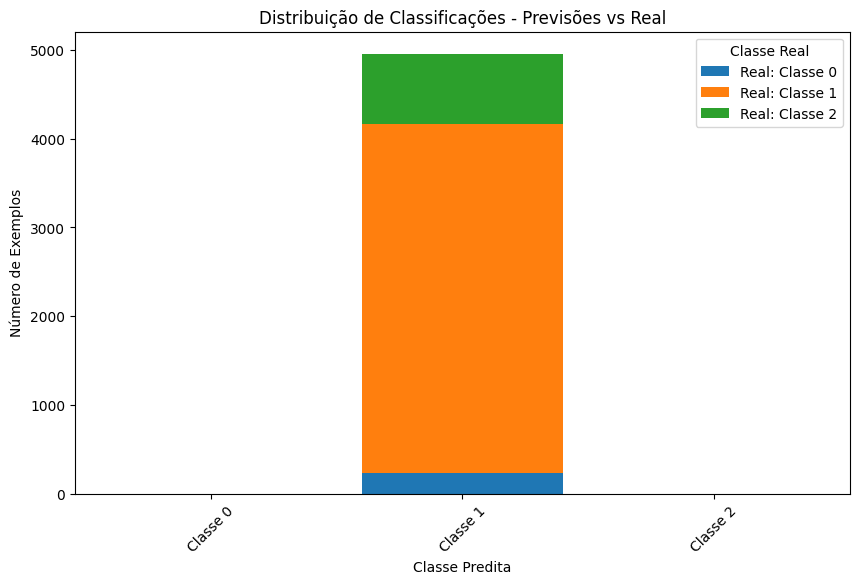

In [30]:
import numpy as np
import tensorflow as tf

# Extrair os rótulos (y_true) do test_dataset
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

# Fazer previsões com o modelo
y_pred = model.predict(test_dataset)
y_pred_classes = np.argmax(y_pred, axis=1)

# Calcular a matriz de confusão
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

conf_matrix = confusion_matrix(y_true, y_pred_classes)

# Plotar a matriz de confusão
labels = [f'Classe {i}' for i in range(conf_matrix.shape[0])]
fig, ax = plt.subplots(figsize=(10, 6))

for i in range(conf_matrix.shape[0]):
    ax.bar(labels, conf_matrix[i], bottom=np.sum(conf_matrix[:i], axis=0), label=f'Real: Classe {i}')

# Adicionar título, rótulos e legenda
ax.set_title('Distribuição de Classificações - Previsões vs Real')
ax.set_xlabel('Classe Predita')
ax.set_ylabel('Número de Exemplos')
ax.legend(title="Classe Real")
plt.xticks(rotation=45)
plt.show()
